<center><h1>Zheng_Yifei_HW8</h1></center>

Name: Yifei Zheng
<br>
Github Username: yyl-ff
<br>
USC ID: 8538054131

## 1. Supervised, Semi-Supervised, and Unsupervised Learning

Import packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans, SpectralClustering
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    roc_curve
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

### (a) Download the Breast Cancer Wisconsin (Diagnostic) Data Set

In [3]:
features = [
    "radius", "texture", "perimeter", "area", "smoothness",
    "compactness", "concavity", "concave_points", "symmetry",
    "fractal_dimension"
]
columns = ["ID", "Diagnosis"] + [
    f"{stat}_{feature}"
    for stat in ["mean", "se", "worst"]
    for feature in features
]

data = pd.read_csv("wdbc.data.txt", header=None, names=columns)
data["Diagnosis"] = data["Diagnosis"].map({"B": 0, "M": 1})

### (b) Monte-Carlo Simulation

#### (i) Supervised Learning

,Accuracy,Precision,Recall,F1,AUC
Set,,,,,
Testing,0.967544,0.974472,0.937302,0.954968,0.993331
Training,0.987179,0.991832,0.973725,0.982677,0.997481


Training Confusion Matrix
[[284   1]
 [  3 167]]
Testing Confusion Matrix
[[69  3]
 [ 2 40]]


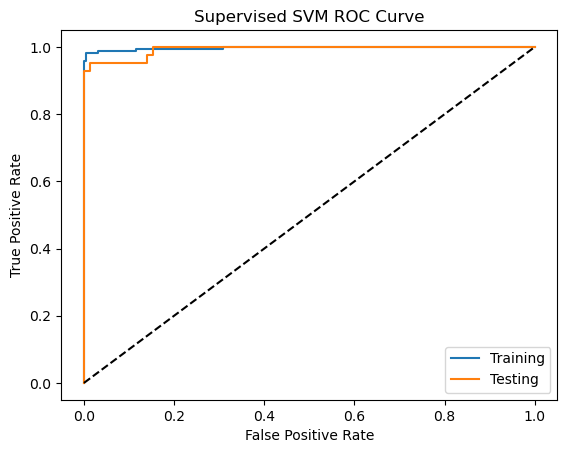

In [5]:
def metrics(y, pred, score):
    return [
        accuracy_score(y, pred),
        precision_score(y, pred),
        recall_score(y, pred),
        f1_score(y, pred),
        roc_auc_score(y, score)
    ]

def fit_svm(X, y, seed):
    model = GridSearchCV(
        LinearSVC(
            penalty="l1",
            dual=False,
            tol=1e-3,
            max_iter=100000
        ),
        {"C": np.logspace(-3, 3, 7)},
        cv=StratifiedKFold(5, shuffle=True, random_state=seed),
        scoring="accuracy",
        n_jobs=-1
    )
    model.fit(X, y)
    return model.best_estimator_

results = []
X = data.drop(columns=["ID", "Diagnosis"])
y = data["Diagnosis"]

for seed in range(30):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=seed)

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)
    model = fit_svm(X_train, y_train, seed)

    for name, X_set, y_set in [
        ("Training", X_train, y_train),
        ("Testing", X_test, y_test)
    ]:
        pred = model.predict(X_set)
        score = model.decision_function(X_set)
        results.append([name, *metrics(y_set, pred, score)])

    if seed == 0:
        example = model, X_train, X_test, y_train, y_test

columns = ["Set", "Accuracy", "Precision", "Recall", "F1", "AUC"]
supervised_results = pd.DataFrame(results, columns=columns).groupby("Set").mean()
display(supervised_results)

model, X_train, X_test, y_train, y_test = example

for name, X_set, y_set in [
    ("Training", X_train, y_train),
    ("Testing", X_test, y_test)
]:
    score = model.decision_function(X_set)
    fpr, tpr, _ = roc_curve(y_set, score)
    plt.plot(fpr, tpr, label=name)
    print(f"{name} Confusion Matrix")
    print(confusion_matrix(y_set, model.predict(X_set)))

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Supervised SVM ROC Curve")
plt.legend()
plt.show()

#### (ii) Semi-Supervised Learning/ Self-training

##### (A)

In [7]:
def initialize_self_training(X, y, seed):
    rng = np.random.default_rng(seed)
    labeled = np.concatenate([
        rng.choice(np.where(y == label)[0], np.sum(y == label) // 2, replace=False)
        for label in [0, 1]
    ])
    unlabeled = np.setdiff1d(np.arange(len(y)), labeled)
    model = fit_svm(X[labeled], y[labeled], seed)
    return model, labeled, unlabeled

##### (B)

,Accuracy,Precision,Recall,F1,AUC
Set,,,,,
Testing,0.960526,0.963541,0.929365,0.945417,0.992130
Training,0.978168,0.982758,0.958627,0.970407,0.995081


Training Confusion Matrix
[[284   1]
 [  5 165]]
Testing Confusion Matrix
[[69  3]
 [ 2 40]]


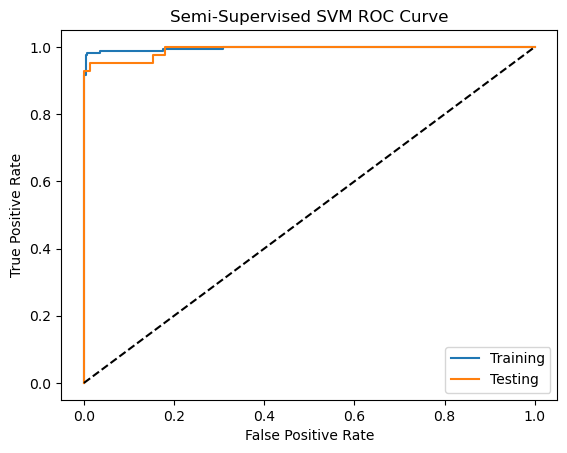

In [9]:
def self_train(X, y, seed):
    model, labeled, unlabeled = initialize_self_training(X, y, seed)
    X_labeled, y_labeled = X[labeled], y[labeled]
    C = model.C

    while len(unlabeled):
        distances = np.abs(model.decision_function(X[unlabeled]))
        index = unlabeled[np.argmax(distances)]
        label = model.predict(X[index].reshape(1, -1))[0]

        X_labeled = np.vstack([X_labeled, X[index]])
        y_labeled = np.append(y_labeled, label)
        unlabeled = unlabeled[unlabeled != index]

        model = LinearSVC(
            penalty="l1",
            dual=False,
            C=C,
            tol=1e-3,
            max_iter=100000
        ).fit(X_labeled, y_labeled)

    return model

results = []

for seed in range(30):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=seed)

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)
    y_train = y_train.to_numpy()
    y_test = y_test.to_numpy()
    model = self_train(X_train, y_train, seed)

    for name, X_set, y_set in [
        ("Training", X_train, y_train),
        ("Testing", X_test, y_test)
    ]:
        pred = model.predict(X_set)
        score = model.decision_function(X_set)
        results.append([name, *metrics(y_set, pred, score)])

    if seed == 0:
        example = model, X_train, X_test, y_train, y_test

semi_results = pd.DataFrame(results, columns=columns).groupby("Set").mean()
display(semi_results)

model, X_train, X_test, y_train, y_test = example

for name, X_set, y_set in [
    ("Training", X_train, y_train),
    ("Testing", X_test, y_test)
]:
    score = model.decision_function(X_set)
    fpr, tpr, _ = roc_curve(y_set, score)
    plt.plot(fpr, tpr, label=name)
    print(f"{name} Confusion Matrix")
    print(confusion_matrix(y_set, model.predict(X_set)))

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Semi-Supervised SVM ROC Curve")
plt.legend()
plt.show()

#### (iii) Unsupervised Learning

##### (A)

In [11]:
def fit_kmeans(X, seed):
    return KMeans(
        n_clusters=2,
        init="random",
        n_init=50,
        random_state=seed
    ).fit(X)

K-means runs 50 times with different random starting points. It keeps the result with the lowest inertia. This helps avoid a local minimum.

##### (B)

,Accuracy,Precision,Recall,F1,AUC
0,0.910183,0.923846,0.828235,0.873242,0.974864


Training Confusion Matrix
[[277   8]
 [ 33 137]]


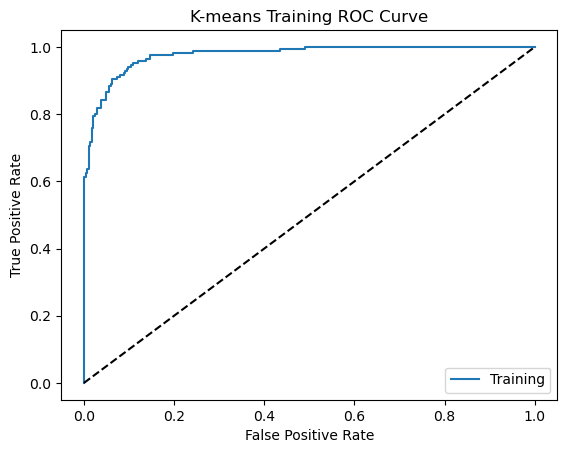

In [13]:
def kmeans_predictions(model, X_train, y_train, X_set):
    train_distances = model.transform(X_train)
    cluster_labels = np.array([
        int(y_train[np.argsort(train_distances[:, cluster])[:30]].mean() >= 0.5)
        for cluster in range(2)
    ])

    distances = model.transform(X_set)
    pred = cluster_labels[np.argmin(distances, axis=1)]
    probabilities = np.exp(-distances - (-distances).max(axis=1, keepdims=True))
    probabilities /= probabilities.sum(axis=1, keepdims=True)
    score = probabilities[:, cluster_labels == 1].sum(axis=1)
    return pred, score

results = []
kmeans_runs = []

for seed in range(30):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=seed)
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)
    y_train = y_train.to_numpy()
    y_test = y_test.to_numpy()

    model = fit_kmeans(X_train, seed)
    pred, score = kmeans_predictions(model, X_train, y_train, X_train)

    results.append(metrics(y_train, pred, score))
    kmeans_runs.append((model, X_train, X_test, y_train, y_test))

training_results = pd.DataFrame(results, columns=columns[1:], index=["Training"] * 30).mean().to_frame().T
display(training_results)
model, X_train, X_test, y_train, y_test = kmeans_runs[0]
pred, score = kmeans_predictions(model, X_train, y_train, X_train)
fpr, tpr, _ = roc_curve(y_train, score)

print("Training Confusion Matrix")
print(confusion_matrix(y_train, pred))

plt.plot(fpr, tpr, label="Training")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("K-means Training ROC Curve")
plt.legend()
plt.show()

##### (C)

,Accuracy,Precision,Recall,F1,AUC
0,0.905263,0.909638,0.82619,0.864657,0.971869


Testing Confusion Matrix
[[65  7]
 [ 7 35]]


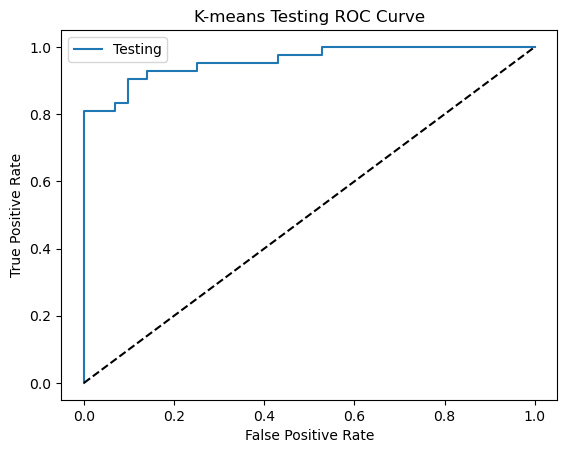

In [15]:
results = []

for model, X_train, X_test, y_train, y_test in kmeans_runs:
    pred, score = kmeans_predictions(model, X_train, y_train, X_test)
    results.append(metrics(y_test, pred, score))

testing_results = pd.DataFrame(results, columns=columns[1:], index=["Testing"] * 30).mean().to_frame().T
display(testing_results)
model, X_train, X_test, y_train, y_test = kmeans_runs[0]
pred, score = kmeans_predictions(model, X_train, y_train, X_test)
fpr, tpr, _ = roc_curve(y_test, score)

print("Testing Confusion Matrix")
print(confusion_matrix(y_test, pred))

plt.plot(fpr, tpr, label="Testing")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("K-means Testing ROC Curve")
plt.legend()
plt.show()

#### (iv) Spectral Clustering

,Accuracy,Precision,Recall,F1,AUC
Set,,,,,
Testing,0.90731,0.919477,0.822222,0.866783,0.889583
Training,0.91011,0.929139,0.822353,0.872344,0.892405


Training Confusion Matrix
[[277   8]
 [ 32 138]]
Testing Confusion Matrix
[[66  6]
 [ 5 37]]


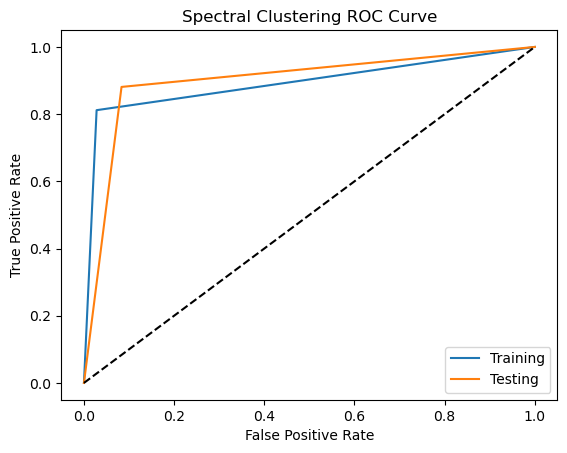

In [17]:
from sklearn.metrics.pairwise import rbf_kernel

results = []
spectral_runs = []

for seed in range(30):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=seed)
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)
    y_train = y_train.to_numpy()
    y_test = y_test.to_numpy()
    X_all = np.vstack([X_train, X_test])
    similarity = rbf_kernel(X_all, gamma=0.001)

    clusters = SpectralClustering(n_clusters=2, affinity="precomputed", n_init=20, random_state=seed).fit_predict(similarity)
    train_clusters = clusters[:len(X_train)]
    test_clusters = clusters[len(X_train):]
    cluster_scores = np.array([
        y_train[train_clusters == cluster].mean()
        for cluster in range(2)
    ])

    for name, cluster_set, y_set in [
        ("Training", train_clusters, y_train),
        ("Testing", test_clusters, y_test)
    ]:
        score = cluster_scores[cluster_set]
        pred = (score >= 0.5).astype(int)
        results.append([name, *metrics(y_set, pred, score)])

    if seed == 0:
        spectral_example = (train_clusters, test_clusters, y_train, y_test, cluster_scores)

spectral_results = pd.DataFrame(results, columns=columns).groupby("Set").mean()
display(spectral_results)
train_clusters, test_clusters, y_train, y_test, cluster_scores = spectral_example

for name, cluster_set, y_set in [
    ("Training", train_clusters, y_train),
    ("Testing", test_clusters, y_test)
]:
    score = cluster_scores[cluster_set]
    pred = (score >= 0.5).astype(int)
    fpr, tpr, _ = roc_curve(y_set, score)
    plt.plot(fpr, tpr, label=name)
    print(f"{name} Confusion Matrix")
    print(confusion_matrix(y_set, pred))

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Spectral Clustering ROC Curve")
plt.legend()
plt.show()

#### (v) Compare

In [19]:
comparison = pd.DataFrame({
    "Supervised": supervised_results.loc["Testing"],
    "Semi-Supervised": semi_results.loc["Testing"],
    "K-means": testing_results.iloc[0],
    "Spectral Clustering": spectral_results.loc["Testing"]
}).T

display(comparison)

,Accuracy,Precision,Recall,F1,AUC
Supervised,0.967544,0.974472,0.937302,0.954968,0.993331
Semi-Supervised,0.960526,0.963541,0.929365,0.945417,0.992130
K-means,0.905263,0.909638,0.826190,0.864657,0.971869
Spectral Clustering,0.907310,0.919477,0.822222,0.866783,0.889583


The supervised model has the best testing results. The semi-supervised model is close to the supervised model, but its results are slightly lower. K-means and spectral clustering perform worse because they do not use the training labels. The results agree with the expected outcomes.

## 2. Active Learning Using Support Vector Machines

### (a) Download the banknote authentication Data Set

In [21]:
from sklearn.pipeline import Pipeline

banknote = pd.read_csv(
    "data_banknote_authentication.txt",
    header=None,
    names=["Variance", "Skewness", "Curtosis", "Entropy", "Class"]
)

X_banknote = banknote.drop(columns="Class")
y_banknote = banknote["Class"]
X_train_bank, X_test_bank, y_train_bank, y_test_bank = train_test_split(X_banknote, y_banknote, test_size=472, random_state=42)
X_train_array = X_train_bank.to_numpy()
X_test_array = X_test_bank.to_numpy()
y_train_array = y_train_bank.to_numpy()
y_test_array = y_test_bank.to_numpy()
sizes = np.arange(10, 901, 10)

### (b) Repeat each of the following two procedures 50 times

#### (i) Passive

In [27]:
def initial_pool(rng):
    return np.concatenate([
        rng.choice(np.where(y_train_array == label)[0], 5, replace=False)
        for label in [0, 1]
    ])

def fit_bank_svm(X, y, seed):
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", LinearSVC(penalty="l1", dual=False, tol=1e-3, max_iter=100000, random_state=seed))
    ])
    search = GridSearchCV(
        model,
        {"svm__C": [0.03, 0.1, 0.3, 1, 3]},
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=seed),
        scoring="accuracy",
        n_jobs=1
    )
    search.fit(X, y)
    return search.best_estimator_

passive_errors = np.zeros((50, len(sizes)))

for run in range(50):
    rng = np.random.default_rng(run)
    first = initial_pool(rng)
    remaining = np.setdiff1d(np.arange(len(y_train_array)), first)
    rng.shuffle(remaining)
    order = np.concatenate([first, remaining])

    for i, size in enumerate(sizes):
        indices = order[:size]
        model = fit_bank_svm(X_train_array[indices], y_train_array[indices], run)
        passive_errors[run, i] = 1 - model.score(X_test_array, y_test_array)

#### (ii) Active

In [29]:
active_errors = np.zeros((50, len(sizes)))
for run in range(50):
    rng = np.random.default_rng(run)
    selected = initial_pool(rng)

    for i, size in enumerate(sizes):
        model = fit_bank_svm(X_train_array[selected], y_train_array[selected], run)
        active_errors[run, i] = 1 - model.score(X_test_array, y_test_array)

        if size < len(y_train_array):
            remaining = np.setdiff1d(np.arange(len(y_train_array)), selected)
            distances = np.abs(model.decision_function(X_train_array[remaining]))
            closest = remaining[np.argsort(distances)[:10]]
            selected = np.append(selected, closest)

### (c) Average the 50 test errors

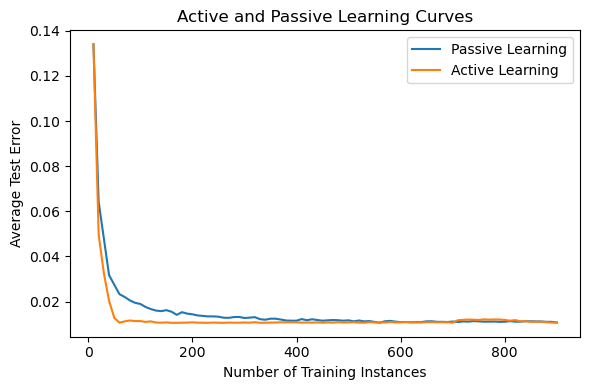

In [31]:
passive_mean = passive_errors.mean(axis=0)
active_mean = active_errors.mean(axis=0)

plt.figure(figsize=(6, 4))
plt.plot(sizes, passive_mean, label="Passive Learning")
plt.plot(sizes, active_mean, label="Active Learning")
plt.xlabel("Number of Training Instances")
plt.ylabel("Average Test Error")
plt.title("Active and Passive Learning Curves")
plt.legend()
plt.tight_layout()
plt.show()

Active learning works better than passive learning when the training set is small. Its test error drops faster because it chooses the points closest to the SVM boundary. These points are usually more useful for training. When more training data are added, the two methods become very similar. In the end, both methods have a test error of about 1%. Overall, active learning is more helpful when we only have a small amount of labeled data.